# Base integrada e estudo de eventos: notícias × Bitcoin

**Semanas de 08/10 e 15/10.** Primeiro corrigimos um vazamento na base estruturada e juntamos as duas trilhas do
projeto (mercado/macro + notícias do GDELT) numa base única. Depois testamos a hipótese central da parte não
estruturada:

> **O sentimento das notícias antecipa a direção do BTC?**

Convenções iguais às do `struc_data.ipynb`: α = 0,05, log-retornos e testes não paramétricos quando há caudas pesadas.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA = Path.cwd().parent / "data"
ALPHA = 0.05

# Mesma paleta e tema do struc_data.ipynb
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GRAY = "#8a8985"
CMAP_DIV = sns.diverging_palette(250, 15, s=75, l=50, center="light", as_cmap=True)
sns.set_theme(style="whitegrid", rc={
    "axes.prop_cycle": plt.cycler(color=C), "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

def veredito(p, h0):
    print(f"   H0: {h0}")
    print(f"   p-valor = {p:.4g} -> {'REJEITA' if p < ALPHA else 'NÃO rejeita'} H0 (α = {ALPHA})")

## 1. Correção de vazamento: defasagem de publicação das séries macro

O FRED data cada observação mensal pelo **início do mês de referência**: o CPI de janeiro fica em 01/01, mas o BLS só o
divulga por volta de 10 a 15 de fevereiro. Como a base faz *forward fill* a partir dessa data, o valor do CPI de janeiro
aparecia em 01/01, **cerca de 45 dias antes de existir**. Qualquer modelo treinado assim estaria usando o futuro.

**Correção:** cada série é deslocada pela sua defasagem de publicação (`PUBLICATION_LAGS` em `config.py`), em
`DataProcessing.apply_publication_lag`, aplicada na unificação.

,defasagem (dias)
US_CPI,45
GERMANY_CPI,55
FRANCE_CPI,55
ITALY_CPI,55
UK_CPI,55
JAPAN_CPI,55
CHINA_CPI,55
INDIA_CPI,55
BRAZIL_CPI,55
SOUTH_AFRICA_CPI,55


,valor do CPI,aparece na base antiga em,aparece na base corrigida em
Date,,,
2022-01-01,282.5430,2022-01-01,2022-02-15
2022-02-01,284.5000,2022-02-01,2022-03-18
2022-03-01,287.6740,2022-03-01,2022-04-15
2022-04-01,288.5610,2022-04-01,2022-05-16
2022-05-01,291.2980,2022-05-01,2022-06-15
2022-06-01,294.9570,2022-06-01,2022-07-16
2022-07-01,294.9130,2022-07-01,2022-08-15
2022-08-01,295.0970,2022-08-01,2022-09-15
2022-09-01,296.3490,2022-09-01,2022-10-16


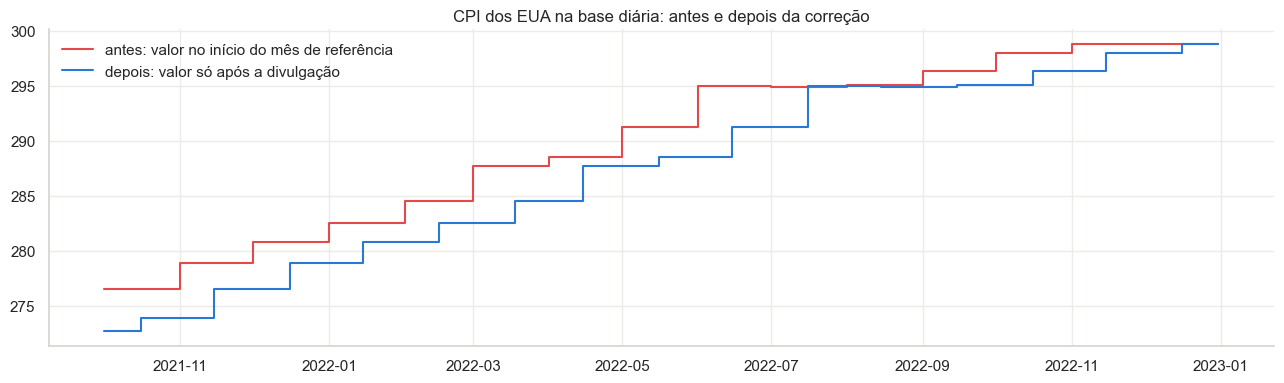

In [2]:
from data_processing.struc_data_processing import DataProcessing
from data_collection.config import PUBLICATION_LAGS

dp = DataProcessing()
raw = dp.load_from_huggingface(apply_lag=False, save=False)   # versão publicada em 17/09
pit = DataProcessing.apply_publication_lag(raw)                # versão corrigida (point-in-time)

display(pd.Series(PUBLICATION_LAGS, name="defasagem (dias)").to_frame())

# Em que dia cada valor do CPI americano "aparece" na base?
mudou = raw["US_CPI"].diff() != 0
exemplo = pd.DataFrame({
    "valor do CPI": raw.loc[mudou, "US_CPI"],
    "aparece na base antiga em": raw.index[mudou],
}).iloc[1:]
exemplo["aparece na base corrigida em"] = exemplo["aparece na base antiga em"] + pd.Timedelta(days=PUBLICATION_LAGS["US_CPI"])
display(exemplo.loc["2022"])

fig, ax = plt.subplots(figsize=(13, 4))
janela = slice("2021-10-01", "2022-12-31")
ax.step(raw.loc[janela].index, raw.loc[janela, "US_CPI"], where="post", color=C[7], label="antes: valor no início do mês de referência")
ax.step(pit.loc[janela].index, pit.loc[janela, "US_CPI"], where="post", color=C[0], label="depois: valor só após a divulgação")
ax.set_title("CPI dos EUA na base diária: antes e depois da correção")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Leitura:** na base antiga, o CPI de cada mês aparecia no dia 1º desse mês; na corrigida, só depois da divulgação. A
EDA da Entrega 1 não é afetada (ela agregava por mês, olhando relações contemporâneas), mas os modelos de previsão
seriam: o vazamento apareceria como um falso poder preditivo das variáveis de inflação e juros mensais.

> A versão no HuggingFace ainda é a antiga. Ao recoletar com as API keys (`main.py`), `unify_data` já aplica a
> defasagem; depois disso, `load_from_huggingface(apply_lag=False)` deve ser usado para não defasar duas vezes.

## 2. Integração das duas trilhas

**Calendário:** o do BTC (7 dias por semana), como decidido na Entrega 1.
**Fuso:** o candle diário do BTC no yfinance vai de 00h a 24h UTC, e os timestamps do GDELT também estão em UTC. Assim, a
linha do dia *t* contém apenas o que já se sabia às 24h UTC de *t*: o fechamento do BTC, o fechamento de todas as bolsas
(a última a fechar, Nova York, fecha às 20h/21h UTC), as séries macro já divulgadas e as notícias publicadas em *t*.

In [3]:
from data_processing.integration import DataIntegration
df = DataIntegration().run()

cob = df.groupby(df.index.year).agg(dias=("BTC_Close", "size"), dias_com_cobertura=("has_news_coverage", "sum"),
                                    noticias=("news_count", "sum"), dias_sem_noticia=("news_count", lambda s: (s == 0).sum()))
display(cob)

Base integrada salva em 'C:\Users\vicbo\Documents\GitHub\MADES\MADES\sources\data\integrated_dataframe.csv' | (3650, 74) | notícias de 2017-01-01 a 2026-01-31


,dias,dias_com_cobertura,noticias,dias_sem_noticia
Date,,,,
2016,363,0,0.0000,0
2017,365,365,"9,790.0000",4
2018,365,365,"13,324.0000",0
2019,365,365,"7,423.0000",1
2020,366,366,"7,214.0000",2
2021,365,365,"8,856.0000",1
2022,365,365,"3,617.0000",1
2023,365,365,"10,091.0000",0
2024,366,366,"11,697.0000",0


A base integrada tem 2016–2025 (3.650 dias). As notícias começam em 2017, então 2016 serve só de "aquecimento" para as
features de mercado (médias móveis, volatilidade de 30 dias). No período 2017–2025, apenas 33 dias não têm nenhuma notícia.

A partir daqui usamos as features construídas em `modeling/features.py` (todas usam informação até *t*). O tom é o
**tom ajustado pela fonte**, ponderado pelo número de notícias.

In [4]:
from modeling.features import build_dataset
N_CLUSTERS = int(pd.read_csv(DATA / "news_clusters.csv")["cluster"].max())
data, groups = build_dataset(df, N_CLUSTERS)
r = data["btc_ret_1d"]
print(f"Base de análise: {data.index.min().date()} a {data.index.max().date()} | {data.shape}")
print({g: len(c) for g, c in groups.items()})

Base de análise: 2017-02-01 a 2025-12-31 | (3256, 136)
{'btc': 17, 'mercado_macro': 60, 'noticias': 44, 'mercado_vol': 6, 'noticias_atencao': 4}


## 3. O sentimento antecipa o retorno do BTC?

#### H11. Correlação defasada entre tom e retorno

Calculamos a correlação de Spearman entre o tom do dia *t* e o retorno do BTC no dia *t + k*, para k de −10 a +10.

- **k > 0** (tom antes do retorno): o sentimento **antecipa** o preço, que é o que seria útil para prever a direção.
- **k < 0** (retorno antes do tom): o sentimento **reage** ao preço.

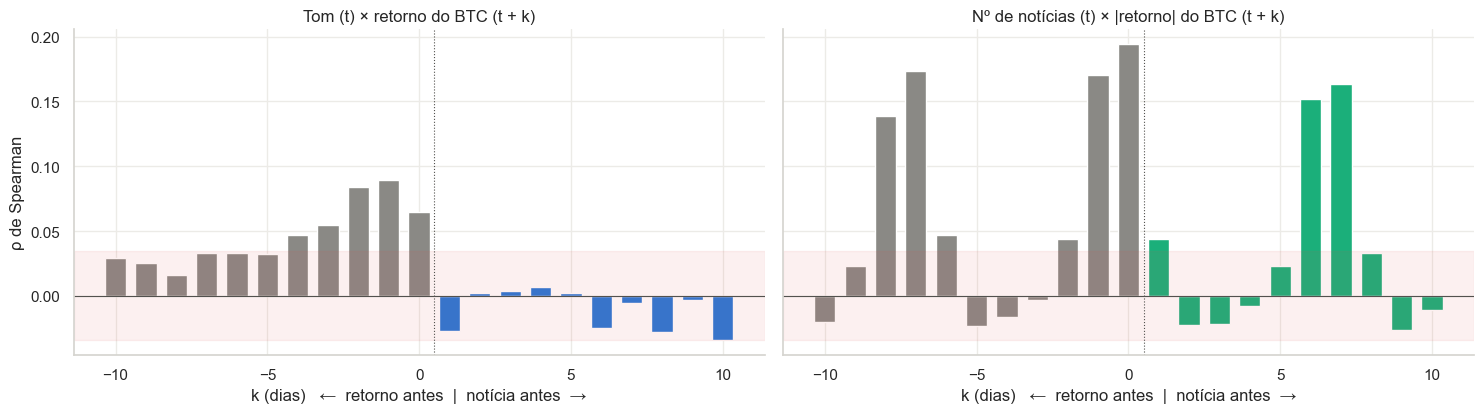

,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10
tom,0.0290,0.0250,0.0160,0.0330,0.0330,0.0330,0.0470,0.0550,0.0840,0.0890,0.0650,-0.0270,0.0030,0.0040,0.0070,0.0020,-0.0250,-0.0050,-0.0280,-0.0030,-0.0340
atencao_vs_vol,-0.0200,0.0230,0.1390,0.1740,0.0470,-0.0240,-0.0160,-0.0040,0.0440,0.1700,0.1940,0.0440,-0.0230,-0.0220,-0.0080,0.0230,0.1520,0.1640,0.0330,-0.0260,-0.0110


Faixa de ±0.034 = não significativo a 5% (aprox.)


In [5]:
lags = range(-10, 11)
cc = pd.DataFrame({
    "tom": [stats.spearmanr(data["news_tone_1d"], r.shift(-k), nan_policy="omit")[0] for k in lags],
    "atencao_vs_vol": [stats.spearmanr(data["news_log_count"], r.abs().shift(-k), nan_policy="omit")[0] for k in lags],
}, index=list(lags))
lim = 1.96 / np.sqrt(len(data))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for ax, col, titulo, cor in [(axes[0], "tom", "Tom (t) × retorno do BTC (t + k)", C[0]),
                             (axes[1], "atencao_vs_vol", "Nº de notícias (t) × |retorno| do BTC (t + k)", C[2])]:
    ax.bar(cc.index, cc[col], color=[cor if k > 0 else GRAY for k in cc.index], width=0.7)
    ax.axhspan(-lim, lim, color=C[7], alpha=0.08)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.axvline(0.5, color="#52514e", lw=0.8, ls=":")
    ax.set_title(titulo)
    ax.set_xlabel("k (dias)   ←  retorno antes  |  notícia antes  →")
axes[0].set_ylabel("ρ de Spearman")
plt.tight_layout()
plt.show()
display(cc.round(3).T)
print(f"Faixa de ±{lim:.3f} = não significativo a 5% (aprox.)")

**Leitura:** as correlações significativas estão nos k **≤ 0**, em cinza: o tom de hoje se relaciona com o retorno de
**hoje e dos dias anteriores**, e não com o de amanhã (em k = +1 ela é praticamente zero). O mesmo vale para a atenção:
o número de notícias acompanha o |retorno| do próprio dia e do dia anterior. É o padrão de uma mídia que **noticia o que
o preço já fez**.

Os picos em k = ±7 no gráfico da direita são **calendário**, e não efeito causal: nos fins de semana há menos notícias
(cerca de 1/3 a menos) e o BTC também oscila menos, então as duas séries têm o mesmo ciclo semanal.

#### H12. Causalidade de Granger entre tom e retorno

- **H0:** o passado de X não melhora a previsão de Y além do próprio passado de Y. Defasagens de 1 a 7 dias.

In [6]:
from statsmodels.tsa.stattools import grangercausalitytests

def granger_p(dados, y, x, maxlag):
    res = grangercausalitytests(dados[[y, x]].dropna(), maxlag=maxlag, verbose=False)
    return {f"lag {l}": res[l][0]["ssr_ftest"][1] for l in res}

g = data[["btc_ret_1d", "news_tone_1d", "news_log_count"]].assign(btc_abs=r.abs()).dropna()
gr = pd.DataFrame({
    "tom → retorno BTC": granger_p(g, "btc_ret_1d", "news_tone_1d", 7),
    "retorno BTC → tom": granger_p(g, "news_tone_1d", "btc_ret_1d", 7),
    "nº notícias → |retorno|": granger_p(g, "btc_abs", "news_log_count", 7),
    "|retorno| → nº notícias": granger_p(g, "news_log_count", "btc_abs", 7),
}).T
display(gr.style.format("{:.4f}").map(lambda v: "font-weight: bold" if v < ALPHA else ""))

,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7
tom → retorno BTC,0.2817,0.4145,0.5678,0.6465,0.7384,0.4430,0.5788
retorno BTC → tom,0.0004,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
nº notícias → |retorno|,0.1033,0.4190,0.0257,0.1360,0.0319,0.0000,0.0000
|retorno| → nº notícias,0.0000,0.0000,0.0003,0.0010,0.0000,0.0001,0.0084


**Leitura:** a causalidade de Granger vai **do preço para a notícia**: o retorno do BTC antecede o tom das notícias com
p < 0,001 em todas as defasagens, e o contrário não é significativo em nenhuma.

Na atenção, o |retorno| antecede fortemente o número de notícias (p < 0,01 em todas as defasagens). O sentido contrário
só fica significativo nas defasagens 6 e 7, de novo o **ciclo semanal**, e não informação nova. Ou seja, também aqui o
preço se move primeiro.

## 4. Estudo de eventos (event study)

O estudo de eventos é a ferramenta clássica de finanças para medir o efeito de um evento no preço, e dá nome ao projeto
(*Market Analysis Driven by Event Studies*). Procedimento:

1. **Evento = choque de sentimento:** dia em que o tom diário fica a mais de 2 desvios-padrão da sua média dos 90 dias
   **anteriores** (z-score só com o passado), em dias com pelo menos 5 notícias. Choques negativos e positivos são
   analisados separadamente.
2. **Declustering:** eventos a menos de 10 dias de outro do mesmo tipo são descartados, para as janelas não se
   sobreporem.
3. **Retorno anormal (AR)** = retorno do BTC − retorno médio na janela de estimação [−120, −11] dias (modelo de média
   constante, o padrão em cripto, que negocia 7 dias por semana).
4. **CAR** (retorno anormal acumulado) em janelas antes e depois do evento, com teste t, Wilcoxon e um **teste placebo**
   (1.000 sorteios de datas falsas), que é robusto a caudas pesadas.

Se o sentimento **antecipa** o preço, o CAR deve aparecer **depois** do evento ([+1, +5]). Se ele **reage**, o CAR
aparece **antes** ([−5, −1]).

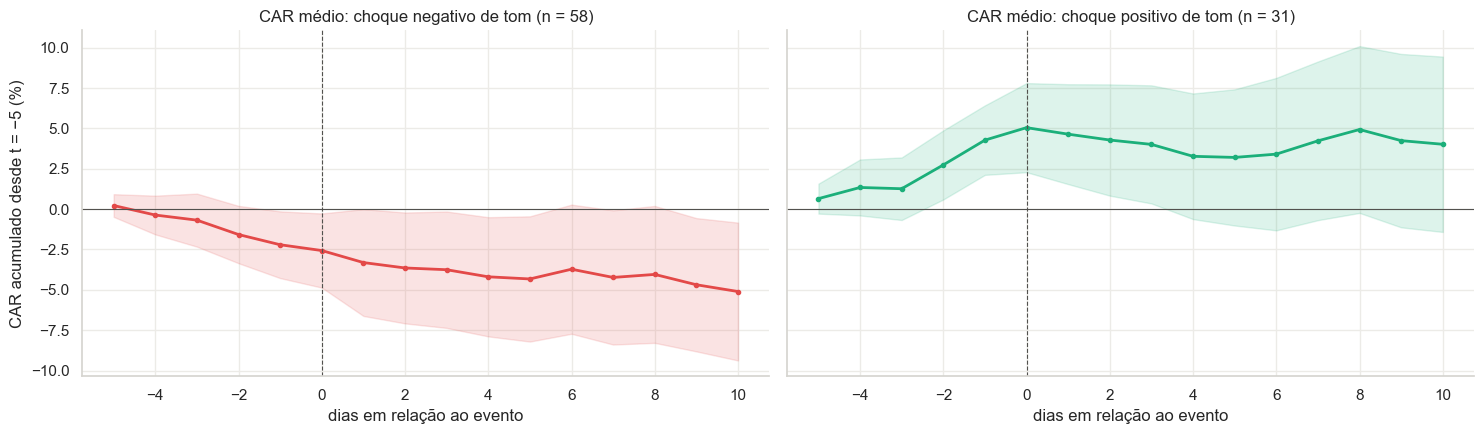


CHOQUE NEGATIVO DE TOM  (n = 58)


,CAR_medio_%,CAR_mediano_%,%_positivos,t,p_t,p_wilcoxon
janela,,,,,,
"[-5, -1]",-2.2080,-0.8210,43.1030,-2.0930,0.0410,0.0850
"[+0, +0]",-0.3600,-0.0350,50.0000,-0.7180,0.4750,0.5590
"[+1, +1]",-0.7440,0.2160,51.7240,-0.7620,0.4490,0.7250
"[+1, +5]",-1.7600,-1.4590,41.3790,-1.1980,0.2360,0.2200
"[+1, +10]",-2.5390,-2.3910,37.9310,-1.5010,0.1390,0.1120



CHOQUE POSITIVO DE TOM  (n = 31)


,CAR_medio_%,CAR_mediano_%,%_positivos,t,p_t,p_wilcoxon
janela,,,,,,
"[-5, -1]",4.2730,3.1940,74.1940,3.8910,0.0010,0.0010
"[+0, +0]",0.7730,0.4670,64.5160,1.1950,0.2420,0.1110
"[+1, +1]",-0.4040,0.2810,54.8390,-0.6080,0.5480,0.7500
"[+1, +5]",-1.8440,0.4750,51.6130,-1.0580,0.2990,0.4210
"[+1, +10]",-1.0300,-0.9630,48.3870,-0.4090,0.6850,0.7790


In [7]:
from modeling.event_study import detect_events, abnormal_returns, car_table, placebo_test

valid = df["news_count"].reindex(data.index) >= 5
ev = {
    "choque negativo de tom": detect_events(data["news_tone_z90"], 2.0, "neg", 10, valid),
    "choque positivo de tom": detect_events(data["news_tone_z90"], 2.0, "pos", 10, valid),
}
ars = {nome: abnormal_returns(r, e) for nome, e in ev.items()}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (nome, ar), cor in zip(axes, ars.items(), [C[7], C[2]]):
    car = ar.cumsum(axis=1) * 100
    m, se = car.mean(), car.std() / np.sqrt(len(car))
    ax.plot(m.index, m, color=cor, lw=2, marker="o", ms=3)
    ax.fill_between(m.index, m - 1.96 * se, m + 1.96 * se, color=cor, alpha=0.15)
    ax.axvline(0, color="#52514e", lw=0.8, ls="--")
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_title(f"CAR médio: {nome} (n = {len(ar)})")
    ax.set_xlabel("dias em relação ao evento")
axes[0].set_ylabel("CAR acumulado desde t = −5 (%)")
plt.tight_layout()
plt.show()

for nome, ar in ars.items():
    print(f"\n{nome.upper()}  (n = {len(ar)})")
    display(car_table(ar).round(3))

In [8]:
candidatos = data.index[valid & data["news_tone_z90"].notna()]
candidatos = candidatos[(candidatos > candidatos[0] + pd.Timedelta(days=130)) & (candidatos < candidatos[-1] - pd.Timedelta(days=15))]

linhas = []
for nome, e in ev.items():
    for janela in [(-5, -1), (1, 5)]:
        real, sims, p = placebo_test(r, e, candidatos, window=janela, n_iter=1000)
        linhas.append({"evento": nome, "janela": f"[{janela[0]:+d}, {janela[1]:+d}]", "CAR real (%)": real * 100,
                       "CAR placebo médio (%)": sims.mean() * 100, "p-valor placebo": p})
placebo = pd.DataFrame(linhas).set_index(["evento", "janela"])
display(placebo.round(4))

CAR real (%)  CAR placebo médio (%)  p-valor placebo
evento                 janela                                                        
choque negativo de tom [-5, -1]       -2.2078                -0.2062           0.0559
                       [+1, +5]       -1.7598                -0.2824           0.1528
choque positivo de tom [-5, -1]        4.2733                -0.1980           0.0040
                       [+1, +5]       -1.8442                -0.2441           0.2757

**Leitura:**
- Antes dos **choques positivos** de tom, o BTC acumula um retorno anormal de cerca de **+4%** nos 5 dias anteriores
  (≈ 74% dos eventos com CAR positivo; significativo no teste t, no Wilcoxon e no placebo). Depois do evento, o CAR é
  estatisticamente zero.
- Antes dos **choques negativos**, o CAR é de cerca de **−2%** (significativo no teste t, marginal nos outros), e depois
  ele também não é significativo.

Os dois choques são **precedidos** por movimento de preço na mesma direção e **não são seguidos** por movimento
significativo. Depois dos choques negativos, o CAR médio continua caindo (≈ −2,5% em 10 dias), mas sem significância
(p ≈ 0,14, e o IC do gráfico é largo). Vale acompanhar com mais eventos, mas hoje não é evidência. É a evidência mais direta de que o sentimento do GDELT **reage** ao preço.

#### H13. A atenção da mídia antecipa a volatilidade?

Mesmo que o tom não dê a direção, um pico de **volume de notícias** poderia anunciar dias turbulentos. Evento: número
de notícias a mais de 2 desvios-padrão da média dos 30 dias anteriores. Medimos o |AR| (tamanho do movimento) em torno do
evento, comparado ao |retorno| médio da janela de estimação.

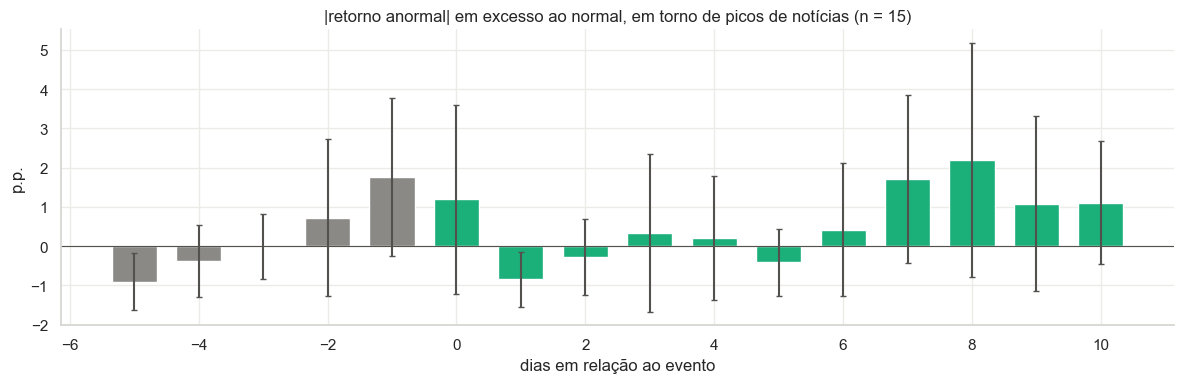

Janela [-5, -1]: excesso médio de |AR| = 0.24 p.p.
   H0: |AR| igual ao normal
   p-valor = 0.5995 -> NÃO rejeita H0 (α = 0.05)
Janela [+0, +0]: excesso médio de |AR| = 1.19 p.p.
   H0: |AR| igual ao normal
   p-valor = 1 -> NÃO rejeita H0 (α = 0.05)
Janela [+1, +5]: excesso médio de |AR| = -0.20 p.p.
   H0: |AR| igual ao normal
   p-valor = 0.3303 -> NÃO rejeita H0 (α = 0.05)


In [9]:
ev_att = detect_events(data["news_count_z30"], 2.0, "pos", 10, valid)
ar_att = abnormal_returns(r, ev_att)
base_abs = pd.Series({e: r.loc[e - pd.Timedelta(days=120): e - pd.Timedelta(days=11)].abs().mean() for e in ar_att.index})
excesso = ar_att.abs().sub(base_abs, axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 4))
m, se = excesso.mean(), excesso.std() / np.sqrt(len(excesso))
ax.bar(m.index, m, color=[C[2] if k >= 0 else GRAY for k in m.index], width=0.7)
ax.errorbar(m.index, m, yerr=1.96 * se, fmt="none", ecolor="#52514e", capsize=2)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_title(f"|retorno anormal| em excesso ao normal, em torno de picos de notícias (n = {len(ar_att)})")
ax.set_xlabel("dias em relação ao evento")
ax.set_ylabel("p.p.")
plt.tight_layout()
plt.show()

for jan in [(-5, -1), (0, 0), (1, 5)]:
    x = excesso.loc[:, jan[0]:jan[1]].mean(axis=1)
    print(f"Janela [{jan[0]:+d}, {jan[1]:+d}]: excesso médio de |AR| = {x.mean():.2f} p.p.")
    veredito(stats.wilcoxon(x).pvalue, "|AR| igual ao normal")

**Leitura:** a média do excesso de |AR| no dia do pico (≈ +1,2 p.p.) é puxada por 2 eventos extremos; a mediana é
negativa e nenhum teste é significativo. Picos isolados de notícias são raros depois do declustering (n = 15), então o
poder do teste é baixo. Por isso a atenção também foi testada como feature contínua no modelo de volatilidade
(notebook de modelagem), que usa todos os dias e não só os picos.

## 5. Algum tema específico antecipa o preço? (por cluster)

Talvez o sentimento *agregado* seja reativo, mas notícias de um tema específico (regulação, política monetária,
mineração) carreguem informação nova. Para cada um dos 11 clusters testamos:

- tom do cluster nos últimos 7 dias (*t*) × retorno do BTC em *t + 1* (direção);
- volume anormal de notícias do cluster (*t*) × |retorno| em *t + 1* (volatilidade).

Com 22 testes, os p-valores são corrigidos por **Holm-Bonferroni**.

In [10]:
from statsmodels.stats.multitest import multipletests
nomes = pd.read_csv(DATA / "news_clusters.csv").groupby("cluster")["nome_cluster"].first()

linhas = []
for c in range(1, N_CLUSTERS + 1):
    for feat, alvo, tipo in [(f"clu{c}_tone_7d", data["target_ret_1d"], "tom → retorno t+1"),
                             (f"clu{c}_count_z30", data["target_absret_1d"], "volume → |retorno| t+1")]:
        rho, p = stats.spearmanr(data[feat], alvo, nan_policy="omit")
        linhas.append({"cluster": c, "tema": nomes[c][:60], "teste": tipo, "rho": rho, "p": p})
res = pd.DataFrame(linhas)
res["p_holm"] = multipletests(res["p"], method="holm")[1]
res["signif. (Holm)"] = res["p_holm"] < ALPHA
with pd.option_context("display.max_colwidth", 70):
    display(res.sort_values("p").round(4))

,cluster,tema,teste,rho,p,p_holm,signif. (Holm)
20,11,York Stock Exchange | New York Stock Exchange,tom → retorno t+1,-0.0593,0.0150,0.3306,False
8,5,EPU_CATS_REGULATION | EPU_POLICY_REGULATORY | LEGISLATION,tom → retorno t+1,-0.0392,0.0259,0.5430,False
21,11,York Stock Exchange | New York Stock Exchange,volume → |retorno| t+1,-0.0270,0.1508,1.0000,False
9,5,EPU_CATS_REGULATION | EPU_POLICY_REGULATORY | LEGISLATION,volume → |retorno| t+1,0.0245,0.1625,1.0000,False
10,6,WB_696_PUBLIC_SECTOR_MANAGEMENT | WB_831_GOVERNANCE | WB_840,tom → retorno t+1,-0.0220,0.2101,1.0000,False
4,3,USPEC_POLICY1 | EPU_ECONOMY_HISTORIC | USPEC_POLITICS_GENERA,tom → retorno t+1,-0.0203,0.2484,1.0000,False
2,2,UNGP_FORESTS_RIVERS_OCEANS | CRISISLEX_CRISISLEXREC | CRISIS,tom → retorno t+1,-0.0162,0.3567,1.0000,False
13,7,WB_1920_FINANCIAL_SECTOR_DEVELOPMENT | EPU_CATS_MONETARY_POL,volume → |retorno| t+1,0.0135,0.4397,1.0000,False
1,1,WB_698_TRADE | TAX_ECON_PRICE | Reuters,volume → |retorno| t+1,0.0135,0.4429,1.0000,False
5,3,USPEC_POLICY1 | EPU_ECONOMY_HISTORIC | USPEC_POLITICS_GENERA,volume → |retorno| t+1,0.0125,0.4765,1.0000,False


**Leitura:** **nenhuma** das 22 relações sobrevive à correção de Holm. Os menores p-valores brutos são do tom do cluster 11
(Bolsa de Nova York) e do cluster 5 (regulação), ambos com ρ entre −0,04 e −0,06, efeitos minúsculos e não significativos
depois da correção. Separar por tema não revela um sinal de direção escondido no agregado.

## 6. Conclusões

**Sobre os dados**
1. **Vazamento corrigido:** séries macro mensais aparecem na base só depois da data de divulgação (defasagens em
   `config.py`). A versão do HuggingFace precisa ser republicada.
2. **Base integrada** pronta (`data/integrated_dataframe.csv`): 3.650 dias, mercado + macro + notícias, alinhada em UTC.

**Sobre a hipótese "o sentimento dá a direção"**

3. **O sentimento do GDELT reage ao preço, não o antecipa.** Isso aparece em três evidências independentes: a correlação
   defasada (H11), a causalidade de Granger do preço para o tom (H12) e o estudo de eventos, em que o CAR fica concentrado
   **antes** dos choques de tom (≈ +4% antes dos positivos) e é nulo depois.
4. Isso é coerente com H3 do `struc_data.ipynb` (direção do BTC quase imprevisível) e com a natureza da fonte: Reuters,
   Bloomberg e CoinDesk cobrem o mercado *depois* que ele se move. Um índice diário de notícias de mídia tradicional
   chega tarde demais para dar a direção do dia seguinte.
5. **Atenção da mídia** (volume de notícias) acompanha a volatilidade, mas também de forma contemporânea ou reativa, e
   parte da relação é só o ciclo semanal. Nenhum tema (cluster) antecipa o preço depois da correção para múltiplos testes.

**Implicações para a modelagem**

6. A proposta "estruturado → volatilidade, GDELT → direção" deve ser **testada fora da amostra**, e não assumida: a
   expectativa, depois desta análise, é que as notícias contribuam pouco. Isso é testado no `modeling_baseline.ipynb` com
   uma ablação (modelos com e sem as features de notícias).
7. Para extrair sinal de direção das notícias, seria preciso informação **mais rápida e mais específica**: granularidade
   horária (o GDELT tem resolução de 15 min), eventos agendados (decisões do Fed, aprovação de ETFs) ou fontes que
   antecedem o mercado (redes sociais). Ficam como próximos passos.